# Mercado laboral en Panamá: salarios, informalidad e inactividad

**Pregunta:** ¿dónde está realmente la desigualdad entre hombres y mujeres en el mercado laboral panameño: en lo que ganan, en la calidad del empleo o en quién llega a trabajar?

**Datos:** tres cuadros de la Encuesta de Mercado Laboral del INEC (Contraloría General de la República de Panamá).

| Cuadro | Contenido | Periodo |
|---|---|---|
| 25 | Empleados por tramo de salario mensual, provincia, sexo y actividad | ver nota en el README |
| 29 | Población no económicamente activa por condición, área y sexo | oct. 2024 y sep. 2025 |
| 39 | Empleo informal no agrícola por provincia y sexo | 2024 y 2025 |

La lógica de limpieza y las métricas están en `src/mercado_laboral.py` (con pruebas en `tests/`); este notebook solo las usa y comenta los resultados.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
import mercado_laboral as ml
import graficos

pd.options.display.float_format = "{:,.1f}".format

## 1. Salarios

El cuadro 25 no trae salarios individuales: trae cuántos empleados hay en cada celda (provincia × sexo × actividad) y qué porcentaje cae en cada tramo salarial. Lo convierto a personas por tramo y estimo la **mediana** interpolando dentro del tramo donde cae la mitad de la población (mediana de datos agrupados).

In [2]:
salarios = ml.cargar_salarios()
print(f"{salarios['personas'].sum():,.0f} empleados en {salarios['provincia'].nunique()} provincias y comarcas")
salarios.head()

1,210,496 empleados en 13 provincias y comarcas


,provincia,sexo,actividad,tramo,personas
0,Bocas del Toro,Hombre,"Agricultura, ganaderia, silvicultura y pesca",Menos de 100,489.1
1,Bocas del Toro,Hombre,Explotacion de minas y canteras,Menos de 100,0.0
2,Bocas del Toro,Hombre,Industria manufacturera - Articulos no durables,Menos de 100,0.0
3,Bocas del Toro,Hombre,Industria manufacturera - Articulos durables,Menos de 100,60.7
4,Bocas del Toro,Hombre,"Suministro de electricidad, gas, vapor y aire ...",Menos de 100,0.0


In [3]:
nacional = ml.mediana_por(salarios, ["sexo"]).set_index("sexo")
brecha_nacional = 1 - nacional.loc["Mujer", "mediana"] / nacional.loc["Hombre", "mediana"]
print(f"Brecha nacional: {brecha_nacional:+.1%} (positivo = las mujeres ganan menos)")
nacional

Brecha nacional: -3.4% (positivo = las mujeres ganan menos)


,mediana,personas
sexo,,
Hombre,745.9,"663,975.0"
Mujer,770.9,"546,521.0"


**Lectura.** Entre personas *empleadas*, la mediana de las mujeres queda ligeramente por encima de la de los hombres. No es lo que uno espera al hablar de "brecha salarial", y la distribución explica por qué:

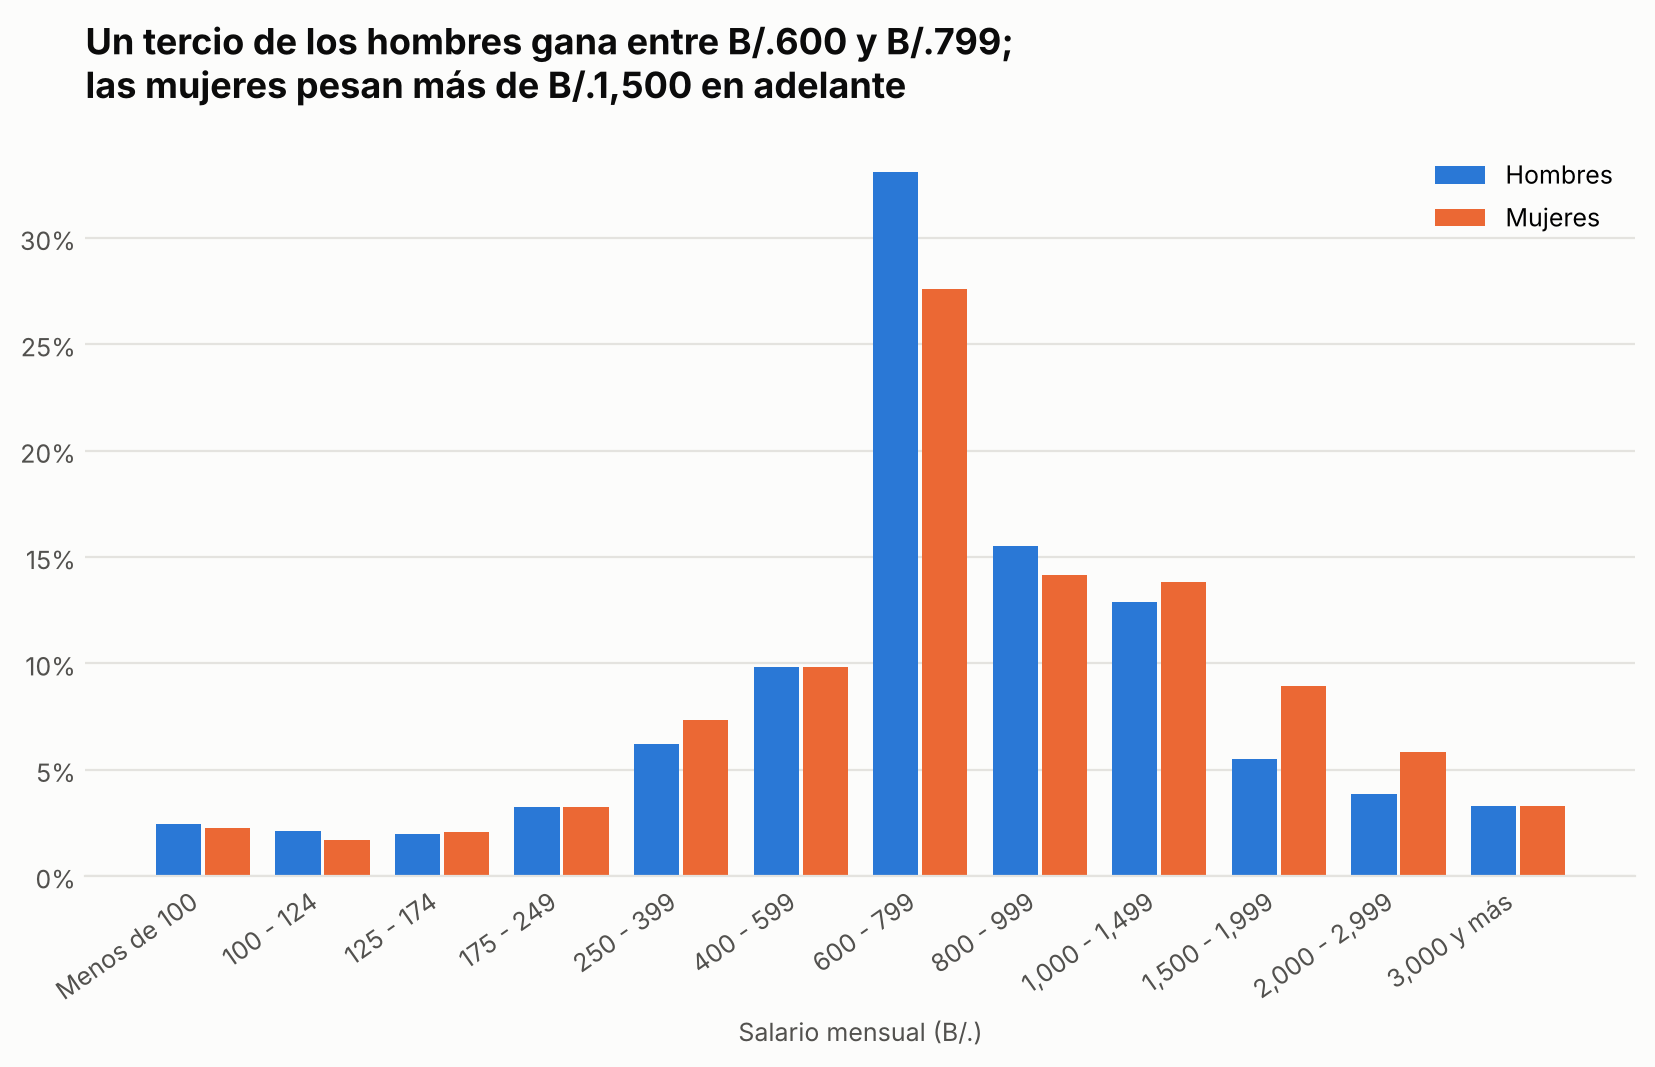

In [4]:
graficos.distribucion_salarial(salarios);

In [5]:
dist = salarios.groupby(["tramo", "sexo"], observed=False)["personas"].sum().unstack()
dist = dist / dist.sum() * 100
resumen = pd.DataFrame({
    "Menos de B/.600": dist.iloc[:6].sum(),
    "B/.600 a 799": dist.loc["600 - 799"],
    "B/.1,500 o más": dist.iloc[9:].sum(),
}).T
resumen

sexo,Hombre,Mujer
Menos de B/.600,25.9,26.4
B/.600 a 799,33.1,27.6
"B/.1,500 o más",12.6,18.0


Los hombres se concentran en el tramo de B/.600–799 (construcción, agro, transporte), mientras que una proporción mayor de mujeres empleadas está en B/.1,500 o más (enseñanza, salud, finanzas, sector público). Es un efecto de **composición**: las mujeres que tienen empleo asalariado están, en promedio, en actividades mejor pagadas. Por eso hay que mirar actividad por actividad.

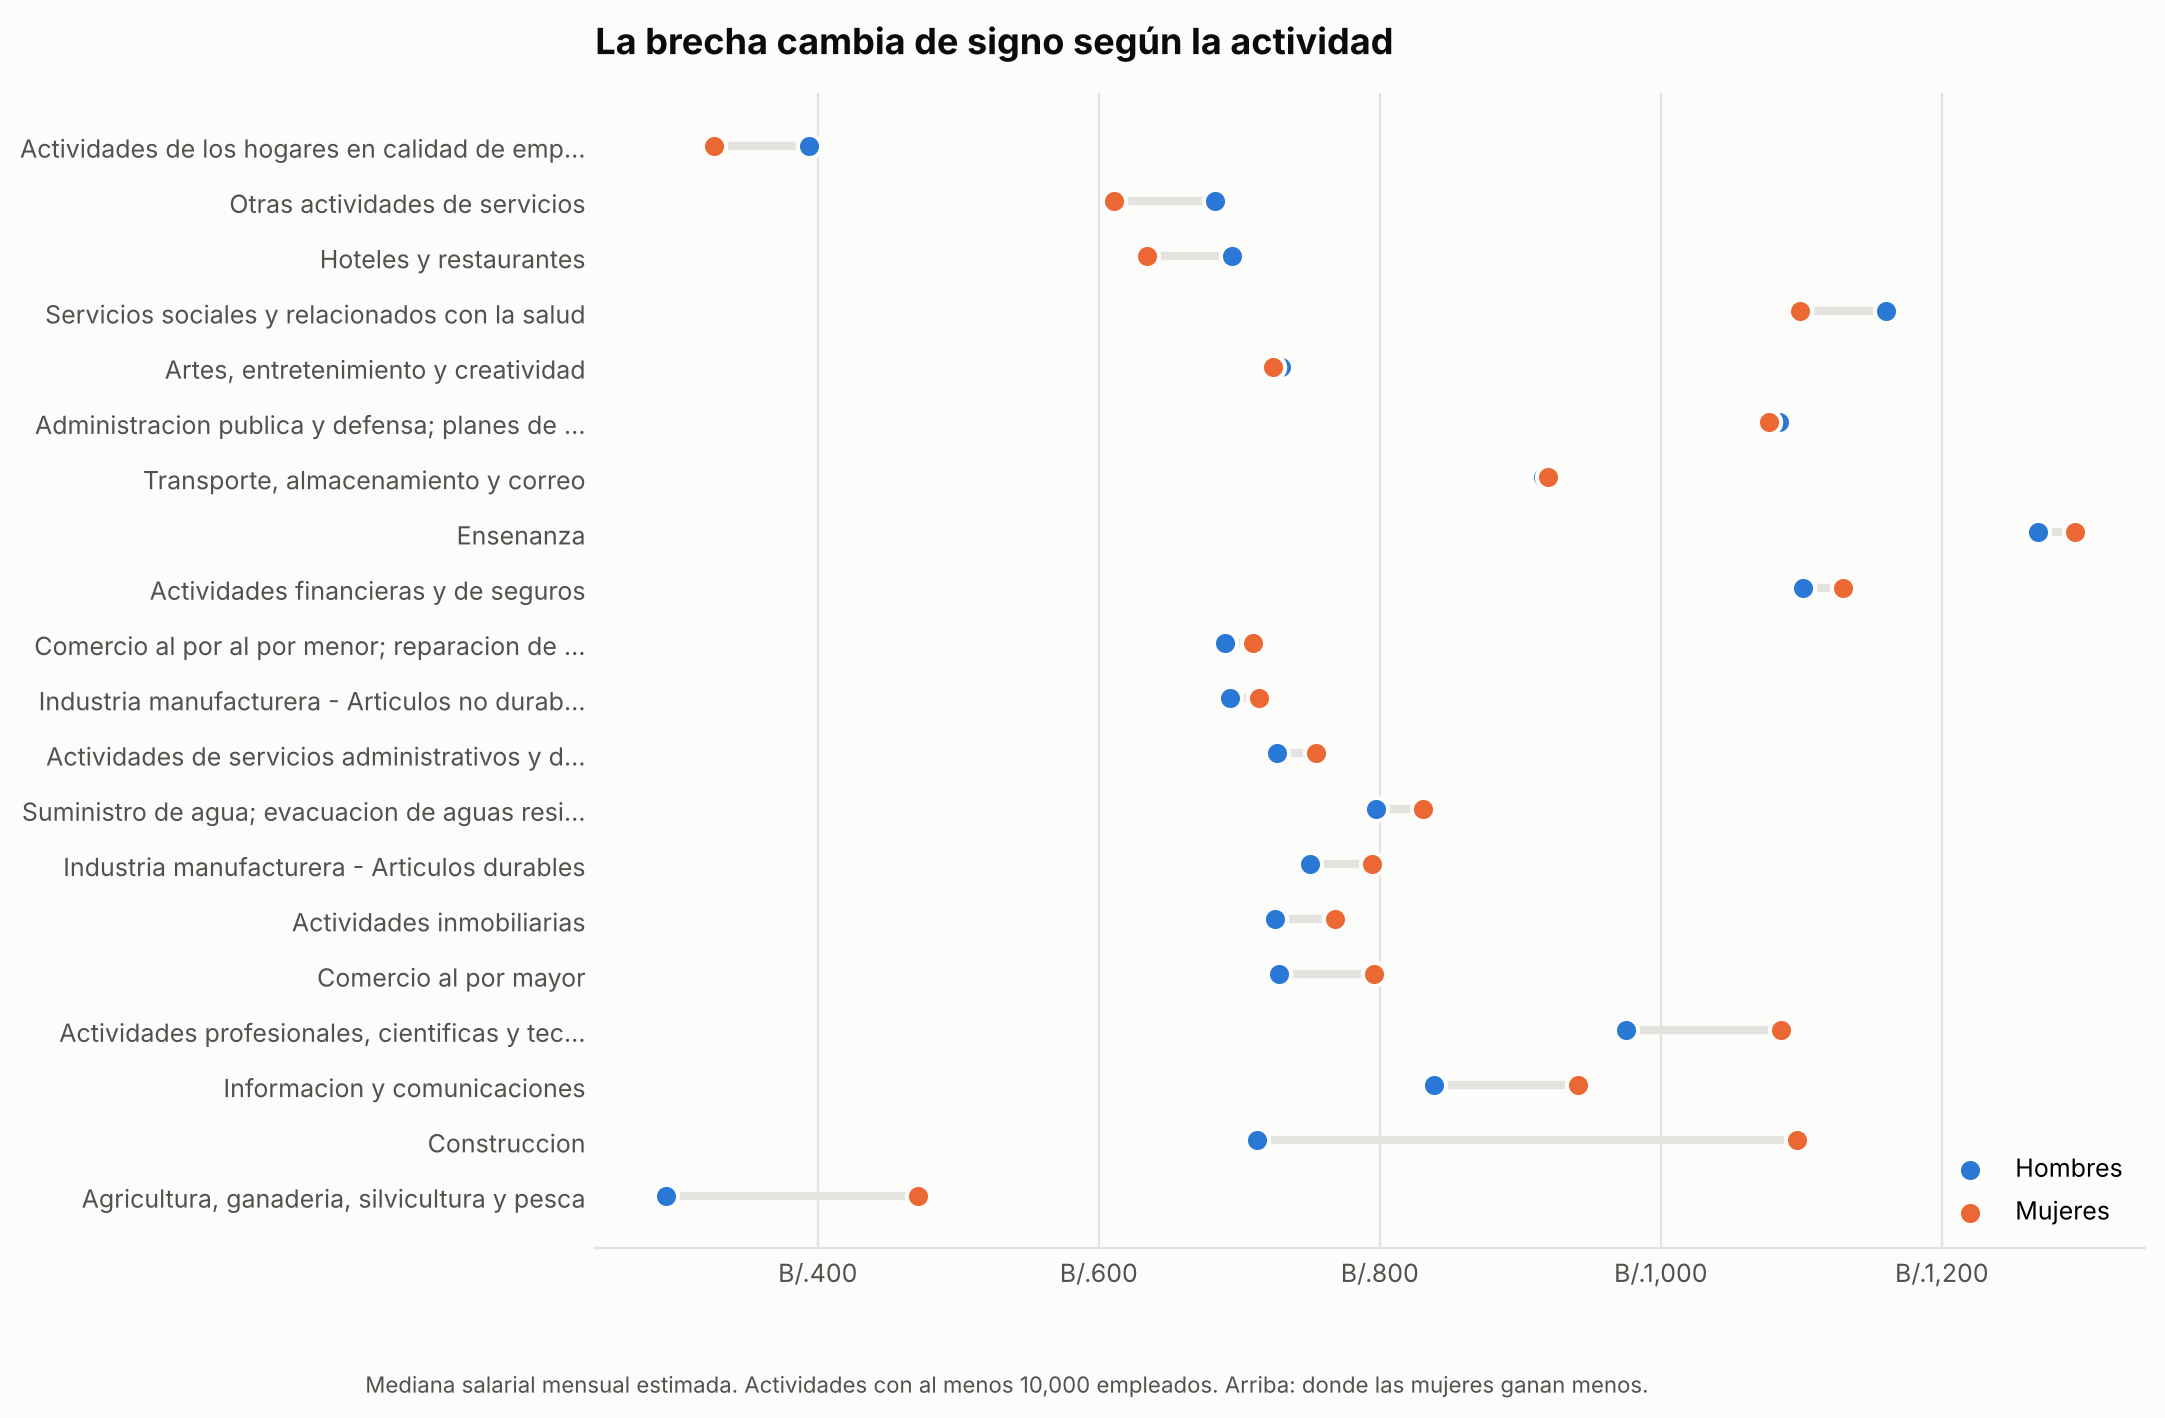

In [6]:
por_actividad = ml.brecha_salarial(ml.mediana_por(salarios, ["actividad", "sexo"]), ["actividad"])
graficos.mediana_por_actividad(por_actividad);

In [7]:
tabla = por_actividad[por_actividad["personas"] >= 10_000].sort_values("brecha", ascending=False)
tabla = tabla.assign(brecha_pct=tabla["brecha"] * 100)[["actividad", "Hombre", "Mujer", "brecha_pct", "personas"]]
tabla.head(6)

sexo,actividad,Hombre,Mujer,brecha_pct,personas
0,Actividades de los hogares en calidad de emple...,393.8,326.3,17.1,"100,013.0"
18,Otras actividades de servicios,683.0,611.1,10.5,"25,402.0"
14,Hoteles y restaurantes,694.7,634.0,8.7,"82,129.0"
19,Servicios sociales y relacionados con la salud,"1,160.5","1,099.2",5.3,"72,329.0"
8,"Artes, entretenimiento y creatividad",729.4,724.1,0.7,"16,540.0"
6,Administracion publica y defensa; planes de se...,"1,083.9","1,076.8",0.7,"124,981.0"


Dentro de una misma actividad la brecha sí aparece donde hay más mujeres en puestos de menor salario: **servicio doméstico, otros servicios, hoteles y restaurantes, y salud**. En construcción y agro la mediana femenina es mucho mayor, pero las mujeres son menos del 10% de esos empleados y suelen ocupar puestos administrativos, no de campo.

Por provincia, el patrón es parecido; en las comarcas las celdas son tan pequeñas que la estimación no es confiable.

In [8]:
por_provincia = ml.brecha_salarial(ml.mediana_por(salarios, ["provincia", "sexo"]), ["provincia"])
por_provincia.assign(brecha_pct=por_provincia["brecha"] * 100).sort_values("personas", ascending=False)[
    ["provincia", "Hombre", "Mujer", "brecha_pct", "personas"]
]

sexo,provincia,Hombre,Mujer,brecha_pct,personas
10,Panamá,786.1,789.1,-0.4,"566,984.0"
11,Panamá Oeste,772.7,773.4,-0.1,"222,242.0"
1,Chiriquí,670.9,718.9,-7.2,"111,373.0"
3,Colón,784.5,791.7,-0.9,"77,028.0"
2,Coclé,643.4,682.4,-6.1,"63,562.0"
12,Veraguas,648.8,743.2,-14.6,"52,630.0"
0,Bocas del Toro,537.5,806.8,-50.1,"36,215.0"
8,Herrera,659.5,734.0,-11.3,"31,085.0"
9,Los Santos,606.9,745.0,-22.8,"22,717.0"
6,Comarca Ngäbe Buglé,297.7,488.3,-64.0,"13,481.0"


## 2. Informalidad

Tasa de informalidad = empleo informal (en empresas formales, en empresas informales y en hogares) ÷ población ocupada no agrícola.

In [9]:
informalidad = ml.cargar_informalidad()
pd.options.display.float_format = "{:,.3f}".format
ml.tasa_informalidad(informalidad, ["anio", "sexo"]).pivot(index="anio", columns="sexo", values="tasa")

sexo,Hombre,Mujer
anio,,
2024,0.486,0.466
2025,0.476,0.466


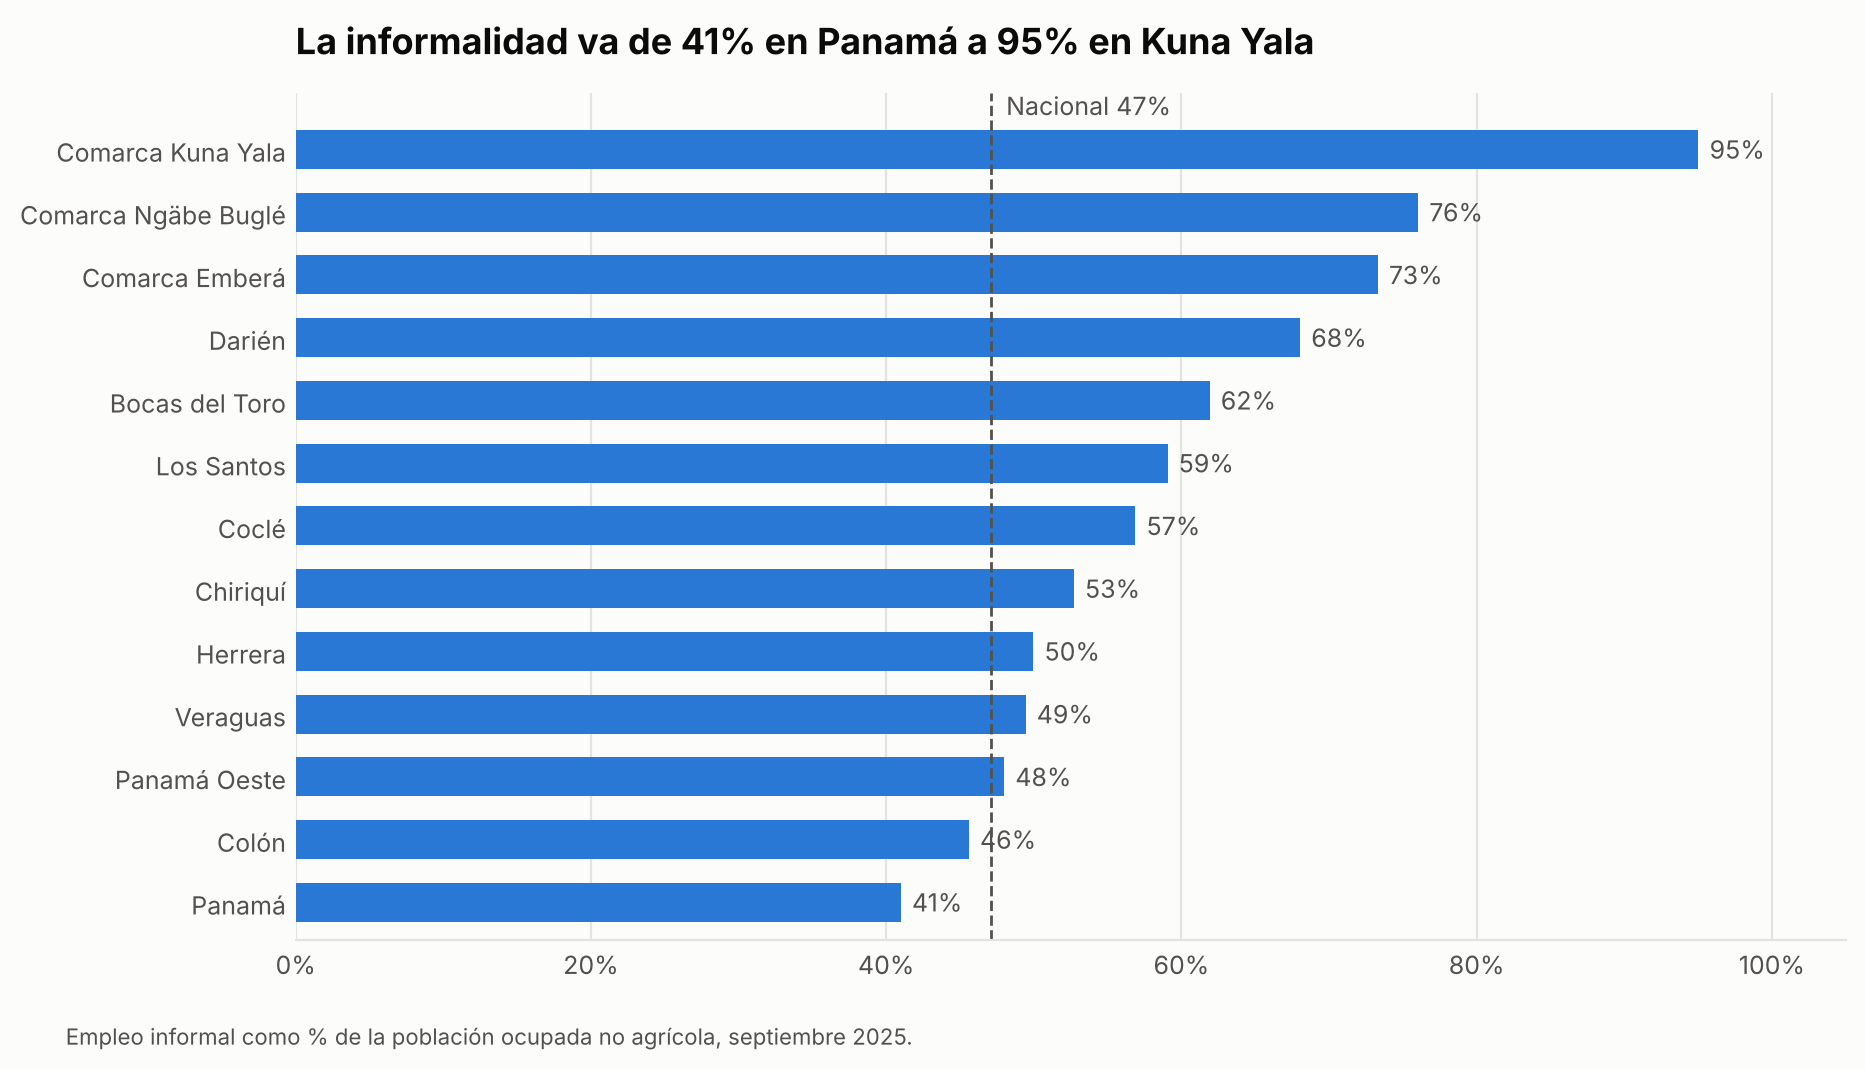

In [10]:
nacional_2025 = ml.tasa_informalidad(informalidad[informalidad["anio"] == 2025], ["anio"])["tasa"].iloc[0]
tasas_2025 = ml.tasa_informalidad(informalidad[informalidad["anio"] == 2025], ["provincia"])
graficos.informalidad_por_provincia(tasas_2025, nacional_2025);

In [11]:
cambio = ml.tasa_informalidad(informalidad, ["provincia", "anio"]).pivot(index="provincia", columns="anio", values="tasa")
cambio["cambio_pp"] = (cambio[2025] - cambio[2024]) * 100
cambio.sort_values("cambio_pp")

anio,2024,2025,cambio_pp
provincia,,,
Comarca Emberá,0.785,0.733,-5.164
Bocas del Toro,0.641,0.619,-2.225
Panamá,0.428,0.410,-1.772
Herrera,0.517,0.500,-1.749
Chiriquí,0.538,0.527,-1.111
Colón,0.465,0.456,-0.942
Darién,0.690,0.680,-0.920
Comarca Kuna Yala,0.942,0.950,0.806
Coclé,0.557,0.569,1.148


In [12]:
componentes = informalidad.groupby("anio")[
    ["informal_sector_formal", "informal_sector_informal", "informal_hogares", "ocupados"]
].sum()
componentes

,informal_sector_formal,informal_sector_informal,informal_hogares,ocupados
anio,,,,
2024,124545,574172,77729,1627199
2025,114069,583020,87901,1665732


**Lectura.** Casi la mitad del empleo no agrícola es informal y el promedio nacional apenas se movió entre 2024 y 2025. Ese promedio esconde dos cosas:

- La diferencia territorial es enorme: de ~41% en la provincia de Panamá a 68% en Darién y más de 70% en las comarcas.
- La composición cambió: bajó el empleo informal *dentro de empresas formales* y subió en empresas informales y en hogares.

Por sexo la tasa es similar; la informalidad es un problema más territorial que de género.

## 3. Población no económicamente activa

Personas en edad de trabajar que ni trabajan ni buscan trabajo. Uso los totales por área (urbana + rural) para el nacional; las provincias suman lo mismo y no deben mezclarse con las áreas.

In [13]:
inactivos = ml.cargar_inactivos()
nac = inactivos[inactivos["nivel"] == "area"]
pd.options.display.float_format = "{:,.0f}".format
por_sexo = nac.groupby(["anio", "sexo"])["personas"].sum().unstack()
por_sexo["% mujeres"] = por_sexo["Mujer"] / por_sexo.sum(axis=1) * 100
por_sexo

sexo,Hombre,Mujer,% mujeres
anio,,,
2024,406208,834656,67
2025,408042,829553,67


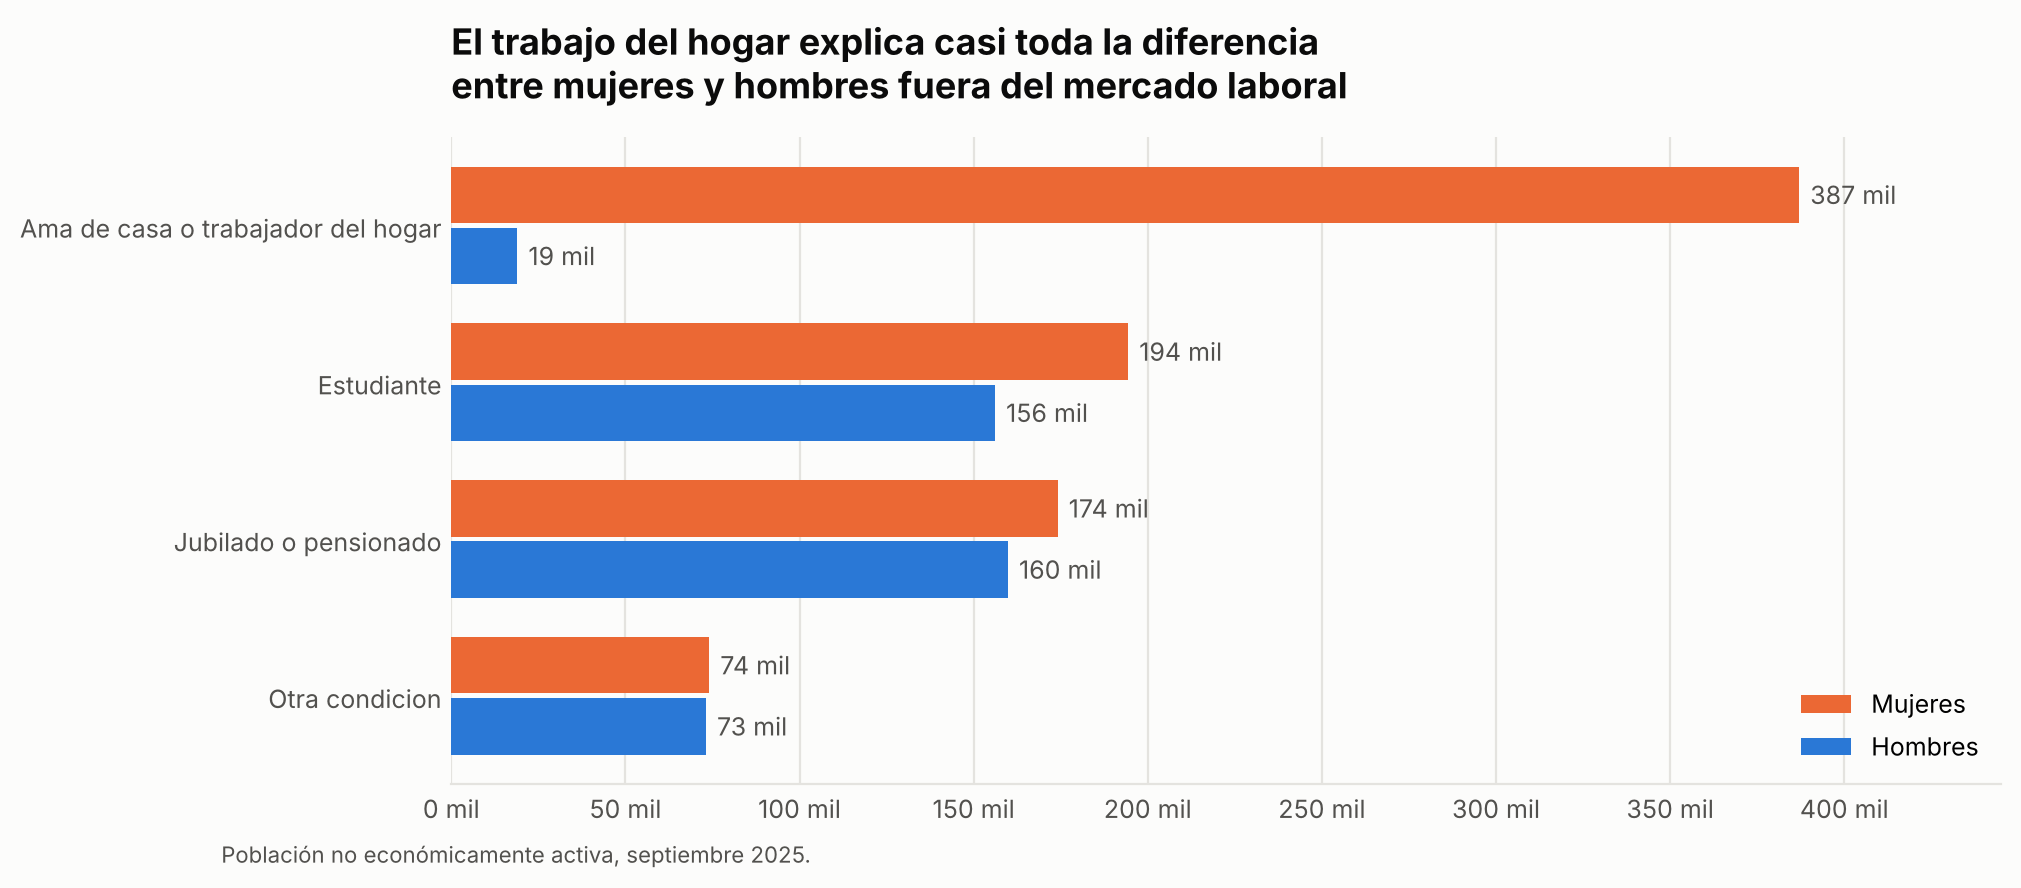

In [14]:
graficos.inactivos_por_condicion(inactivos, 2025);

In [15]:
cond = nac[nac["anio"] == 2025].groupby(["condicion", "sexo"])["personas"].sum().unstack()
cond["mujeres por cada hombre"] = cond["Mujer"] / cond["Hombre"]
pd.options.display.float_format = "{:,.1f}".format
cond.sort_values("mujeres por cada hombre", ascending=False)

sexo,Hombre,Mujer,mujeres por cada hombre
condicion,,,
Ama de casa o trabajador del hogar,18967,387026,20.4
Estudiante,156126,194364,1.2
Jubilado o pensionado,159835,174110,1.1
Otra condicion,73114,74053,1.0


**Lectura.** Dos de cada tres personas fuera del mercado laboral son mujeres. Entre estudiantes y jubilados la diferencia con los hombres es moderada; casi toda la distancia viene de una sola categoría: **ama de casa o trabajador del hogar**, donde hay unas 20 mujeres por cada hombre.

## Conclusiones

1. **La brecha no está donde el titular la pone.** Entre personas empleadas, la mediana salarial estimada de las mujeres es similar o algo mayor que la de los hombres, por un efecto de composición sectorial.
2. **Sí hay brecha dentro de actividades feminizadas y de bajo salario**: servicio doméstico, otros servicios, hoteles y restaurantes.
3. **La desigualdad más grande es de acceso**: ~830 mil mujeres frente a ~408 mil hombres están fuera del mercado laboral, y el trabajo del hogar explica casi toda la diferencia.
4. **La informalidad es territorial**: ronda el 47% nacional sin diferencias fuertes por sexo, pero duplica esa cifra en las comarcas.

### Limitaciones

- Los salarios vienen en tramos con porcentajes redondeados; la mediana es una estimación por interpolación, no un dato publicado por el INEC.
- El cuadro 25 solo cubre **empleados** (asalariados): no incluye cuenta propia ni las personas fuera del mercado laboral, que es justo donde está la mayor diferencia por sexo.
- No se controla por horas trabajadas, ocupación, educación ni antigüedad, así que la brecha por actividad es descriptiva, no causal.
- Son estimaciones de una encuesta por muestreo: las celdas pequeñas (comarcas, actividades con pocos empleados) tienen mucho error.